<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/5.%20Per-ETF%20PTO%20Replication%20Run%20(WBS%3A%203.4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5 Per-ETF PTO Replication Run

The replication run with a second forecast model for PTO. **Per-ETF PTO** fits a separate least-squares regression for each ETF on that ETF's month-end rows in the 9-month fit period: about 8 rows for 8 coefficients, with no penalty and no tuning. D3 found it to be the simplest specification that reproduces the paper's PTO turnover; the paper states neither the per-ETF fit nor the use of month-end rows.

| Strategy | Expected returns |
|---|---|
| Per-ETF PTO | Least-squares forecasts, one regression per ETF on about 8 month-end rows |
| Pooled PTO | One ridge regression for all ETFs on daily rows, penalty 0.1 |
| Classic Markowitz | Mean daily return over the last 126 trading days |

All three run for every λ, on both universes, over the test months. Section 8 checks the four pass criteria with Per-ETF PTO as plain PTO; section 5 compares the forecasts with the paper's Figure 1.

**Inputs:** Daily Prices, Monthly Data, Daily Features, Daily Training Windows, Covariances

**Outputs** (`data` folder):

| File | Folder | Contents |
|---|---|---|
| Per-ETF PTO Forecasts.parquet | processed | Per-ETF forecast of each ETF at each decision date |
| Replication Months (per-ETF).parquet | processed | Monthly returns, fee and turnover of every run |
| Replication Results (per-ETF).csv | reports | Performance of every run next to the paper's values, over 81 and 70 months |
| Replication Checks (per-ETF).csv | reports | Results of all checks, including the pass criteria |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: c2266da, Diagnostic (2026-10-30 16:20)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

from src import backtest, cleaning, config, forecast, variables, windows

# Reload after a fresh clone
for module in (config, cleaning, windows, variables, backtest, forecast):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()
pd.set_option("display.width", 170)

# All check reports of the notebook, saved together at the end
checks = []

## 2. Load the inputs

Only the 9+3 window is used.

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
daily_table = pd.read_parquet(proc / config.FILES["daily_table"])
all_windows = pd.read_parquet(proc / config.FILES["daily_windows"])
cov_table = pd.read_parquet(proc / config.FILES["covariances"])

# Decision calendar, holding-month returns, sample covariances and historical means
calendar = all_windows[all_windows["window"] == "9+3"].reset_index(drop=True)
universes = ("ETF_A", "ETF_B")
returns = {u: backtest.holding_returns(panel, u) for u in universes}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in universes}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in universes}

assert (pd.DatetimeIndex(calendar["decision_date"]) == returns["ETF_A"].index).all()
print(f"{len(calendar)} decision dates, {calendar['month'].iloc[0]} to {calendar['month'].iloc[-1]}")

81 decision dates, 2020-01 to 2026-09


## 3. Forecasts

**Per-ETF PTO.** At each decision date and for each ETF, an ordinary least-squares regression of the 21-day forward return on that ETF's seven features and an intercept, fitted on the ETF's month-end rows in the 9-month fit period (rows whose returns are known before the validation slice starts). Nothing is tuned, so the validation slice is unused.

**Pooled PTO.** One ridge regression for all ETFs on the daily rows of the window, penalty 0.1.

In [4]:
def per_etf_forecasts(universe):
    """Per-ETF least-squares forecasts on the month-end rows of the 9-month fit period."""
    tickers = backtest.tickers_of(universe)
    rows = []
    for _, step in calendar.iterrows():
        fit, val, test = windows.daily_rows_for(daily_table, step, universe)
        fit = fit[fit["month_end"]]
        for t in tickers:
            tr = fit[fit["ticker"] == t]
            x = np.column_stack([np.ones(len(tr)), tr[config.FEATURES].to_numpy(float)])
            beta, *_ = np.linalg.lstsq(x, tr["fwd_return"].to_numpy(float), rcond=None)
            xt = test[test["ticker"] == t][config.FEATURES].to_numpy(float)[0]
            rows.append({"date": step["decision_date"], "month": step["month"], "universe": universe,
                         "ticker": t, "forecast": float(beta[0] + xt @ beta[1:]), "rows": len(tr)})
    return pd.DataFrame(rows)


fc_per_etf = pd.concat([per_etf_forecasts(u) for u in universes], ignore_index=True)
fc_pooled = pd.concat([forecast.build_forecasts(daily_table, calendar, u, backtest.tickers_of(u),
                                                alphas=[config.PTO_ALPHA_GRID[0]]) for u in universes],
                      ignore_index=True)
print(f"Per-ETF: {len(fc_per_etf):,} forecasts, {fc_per_etf['rows'].median():.0f} rows per fit (median)")
print(f"Pooled:     {len(fc_pooled):,} forecasts, "
      f"{(fc_pooled['fit_rows'] + fc_pooled['validation_rows']).median():.0f} rows per fit (median)")

Per-ETF: 1,458 forecasts, 8 rows per fit (median)
Pooled:     1,458 forecasts, 2290 rows per fit (median)


## 4. Checks on the forecasts

Both sets complete and finite, every per-ETF training return known before the validation slice starts, and three random months of per-ETF fits equal to scikit-learn's `LinearRegression`.

In [5]:
rows = []


def add(name, ok, detail):
    """Add one line to the forecast check report."""
    rows.append({"check": name, "status": "PASS" if ok else "FAIL", "detail": detail, "table": "Forecasts"})


for name, f in (("per-ETF", fc_per_etf), ("pooled", fc_pooled)):
    n = sum(len(calendar) * len(backtest.tickers_of(u)) for u in universes)
    add(f"{name} complete", len(f) == n and np.isfinite(f["forecast"]).all(), f"{len(f):,} finite forecasts")

label = daily_table.drop_duplicates("date").set_index("date")["label_date"]
ok = all(label.loc[s["train_start"]:s["fit_end"]].max() < s["validation_start"] for _, s in calendar.iterrows())
add("no look-ahead", ok, "every per-ETF training return is known before the validation slice starts")

# Three random months refitted with scikit-learn
rng = np.random.default_rng(0)
worst = 0.0
for i in rng.choice(len(calendar), 3, replace=False):
    step = calendar.iloc[int(i)]
    fit, val, test = windows.daily_rows_for(daily_table, step, "ETF_A")
    fit = fit[fit["month_end"]]
    for t in config.ETF_A:
        tr = fit[fit["ticker"] == t]
        sk = LinearRegression().fit(tr[config.FEATURES].to_numpy(float), tr["fwd_return"].to_numpy(float))
        pred = sk.predict(test[test["ticker"] == t][config.FEATURES].to_numpy(float))[0]
        ours = fc_per_etf[(fc_per_etf["date"] == step["decision_date"]) & (fc_per_etf["ticker"] == t)
                        & (fc_per_etf["universe"] == "ETF_A")]["forecast"].iloc[0]
        worst = max(worst, abs(pred - ours))
add("matches scikit-learn", worst < 1e-6, f"3 random months x 8 ETFs refit, largest difference {worst:.1e}")

fc_checks = pd.DataFrame(rows)
print(fc_checks.drop(columns="table").to_string(index=False))
checks.append(fc_checks)
if (fc_checks["status"] == "FAIL").any():
    raise RuntimeError("A forecast check failed.")

               check status                                                                    detail
    per-ETF complete   PASS                                                    1,458 finite forecasts
     pooled complete   PASS                                                    1,458 finite forecasts
       no look-ahead   PASS every per-ETF training return is known before the validation slice starts
matches scikit-learn   PASS                3 random months x 8 ETFs refit, largest difference 3.4e-12


## 5. Forecast quality and Figure 1

| Measure | Meaning |
|---|---|
| Spread ratio | Cross-ETF spread of forecasts divided by that of realized returns; 1 = as spread out as realized returns |
| Mean IC | Average monthly rank correlation between forecasts and realized returns |
| Out-of-sample R² | 1 − squared forecast error relative to a forecast of zero |
| Top pick beats average | Share of months in which the top-forecast ETF beat the universe average; 0.5 is chance |

The chart is the view of the paper's Figure 1: the average forecast across ETFs against the average realized return each month. In the paper, the PTO line stays close to the realized line.

                        oos_r2  mean_ic  ic_t_stat  top_pick_beats_average  spread_ratio
model       universe                                                                    
Per-ETF PTO ETF_A     -825.166    0.076      1.899                   0.519        23.259
            ETF_B    -3495.091    0.006      0.159                   0.494        30.084
Pooled PTO  ETF_A       -0.262    0.120      2.130                   0.519         0.532
            ETF_B       -0.419   -0.026     -0.480                   0.432         0.507


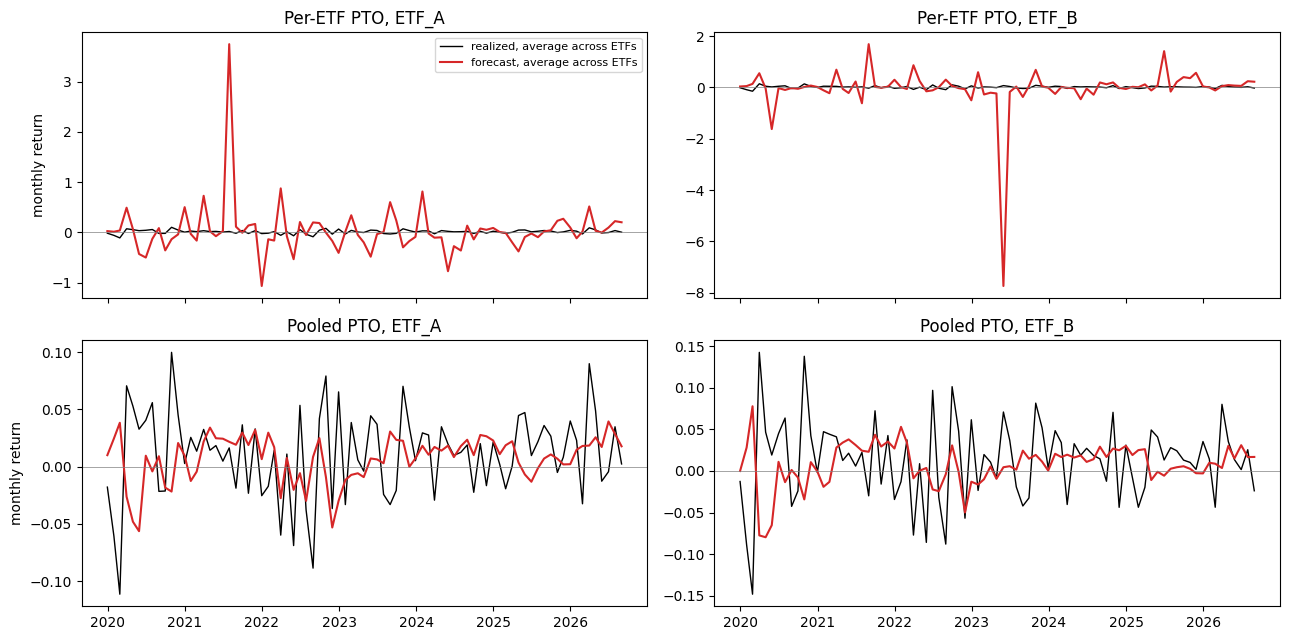


          |average forecast|  spread across ETFs
universe                                        
ETF_A                  0.133               0.362
ETF_B                  0.113               0.416


In [6]:
q = pd.concat([forecast.forecast_quality(fc_per_etf, panel).assign(model="Per-ETF PTO"),
               forecast.forecast_quality(fc_pooled, panel).assign(model="Pooled PTO")])
print(q.reset_index().set_index(["model", "universe"]).round(3).to_string())

# Average forecast and realized return across ETFs, each month
real = panel[["date", "universe", "ticker", "next_return"]]
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
for col, u in enumerate(universes):
    for row, (name, f) in enumerate((("Per-ETF PTO", fc_per_etf), ("Pooled PTO", fc_pooled))):
        ax = axes[row, col]
        g = (f[f["universe"] == u].merge(real, on=["date", "universe", "ticker"])
             .groupby("date")[["forecast", "next_return"]].mean())
        ax.plot(g.index, g["next_return"], color="black", lw=1, label="realized, average across ETFs")
        ax.plot(g.index, g["forecast"], color="tab:red", lw=1.5, label="forecast, average across ETFs")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(f"{name}, {u}")
axes[0, 0].legend(fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("monthly return")
plt.tight_layout()
plt.show()

# Size of the average per-ETF forecast against its spread across ETFs (median over months)
avg = fc_per_etf.groupby(["universe", "date"])["forecast"].mean().groupby("universe").agg(lambda s: s.abs().median())
spread = fc_per_etf.groupby(["universe", "date"])["forecast"].std().groupby("universe").median()
print()
print(pd.DataFrame({"|average forecast|": avg, "spread across ETFs": spread}).round(3).to_string())

## 6. Replication run

All three strategies use the same optimizer, the sample covariance, κ = 0.005, a start from equal weights and the 0.5% fee. Every month of every run is recomputed independently.

In [7]:
def as_matrix(f, universe):
    """Forecasts of one universe as a decision date x ETF table."""
    return f[f["universe"] == universe].pivot(index="date", columns="ticker", values="forecast")[
        backtest.tickers_of(universe)]


runs, weights_by_run = [], {}
for u in universes:
    plans = (("Per-ETF PTO", as_matrix(fc_per_etf, u)), ("Pooled PTO", as_matrix(fc_pooled, u)),
             ("Classic Markowitz", hist_mu[u]))
    for name, mu in plans:
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu, cov_sample[u], lam), returns[u])
            report = backtest.check_accounting(mo, w, returns[u])
            checks.append(report.assign(table=f"Backtest {u} {name} {lam}"))
            runs.append(mo.assign(strategy=name, universe=u, lam=lam))
            weights_by_run[(name, u, lam)] = w

rep_months = pd.concat(runs, ignore_index=True)[
    ["strategy", "universe", "lam", "date", "month", "gross", "fee", "net", "turnover", "held", "effective_n"]]
acc = pd.concat([c for c in checks if str(c["table"].iloc[0]).startswith("Backtest")])
cols_ok = variables.check_table(rep_months, "Replication Months")
checks.append(cols_ok.assign(table="Replication Months"))
print(f"{rep_months.groupby(['strategy', 'universe', 'lam']).ngroups} runs; accounting checks: "
      f"{len(acc)} run, {(acc['status'] == 'FAIL').sum()} failed; "
      f"column checks: {cols_ok['status'].value_counts().to_dict()}")
if (acc["status"] == "FAIL").any() or (cols_ok["status"] == "FAIL").any():
    raise RuntimeError("A backtest check failed.")

30 runs; accounting checks: 150 run, 0 failed; column checks: {'PASS': 12}


## 7. Results next to Table 3

First 70 test months. Per-ETF PTO is compared with the paper's PTO row and classic Markowitz with its MVO row; pooled PTO has no counterpart in the paper.

First 70 months
                                 turnover  paper_turnover  ann_vol  paper_ann_vol  sharpe  paper_sharpe  max_drawdown  paper_max_drawdown  effective_n
strategy          universe lam                                                                                                                        
Classic Markowitz ETF_A    0.1      0.170           0.194    0.196          0.248   0.717         0.654        -0.198              -0.312        1.004
                           1.0      0.180           0.248    0.178          0.236   0.780         0.440        -0.170              -0.312        1.324
                           10.0     0.127           0.142    0.097          0.108   0.519         0.285        -0.144              -0.213        2.136
                           20.0     0.081           0.091    0.072          0.078   0.392         0.248        -0.125              -0.170        2.019
                           50.0     0.046           0.045    0.061          0.

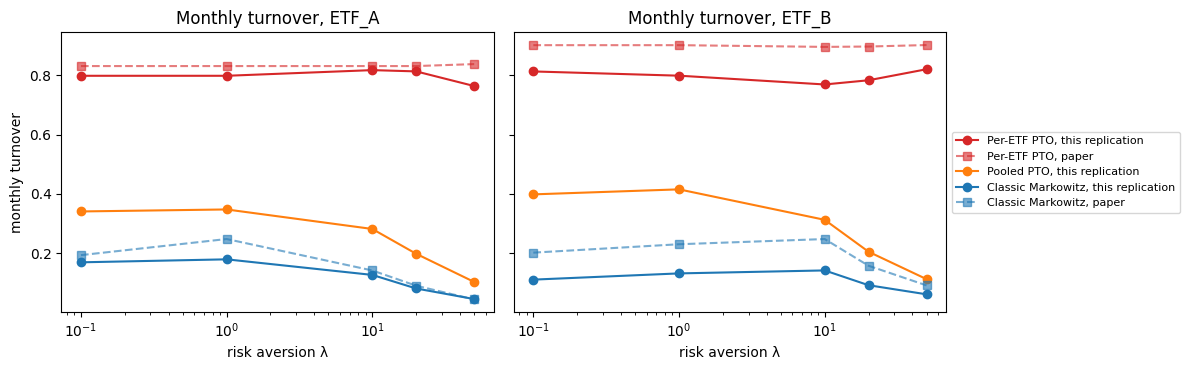

In [8]:
def summarize(rows):
    """Performance metrics of every run in `rows`, one row per strategy, universe and λ."""
    out = pd.DataFrame([backtest.metrics(g).rename(k) for k, g in rows.groupby(["strategy", "universe", "lam"])])
    out.index.names = ["strategy", "universe", "lam"]
    return out


metric_names = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover"]
paper = pd.concat([backtest.paper_rows("PTO").assign(strategy="Per-ETF PTO"),
                   backtest.paper_rows("MVO").assign(strategy="Classic Markowitz")]
                  ).set_index(["strategy", "universe", "lam"])


def side_by_side(table):
    """Metrics of each run joined with the paper's values for the same strategy, universe and λ."""
    return table[metric_names + ["effective_n"]].join(paper.add_prefix("paper_"))


full = summarize(rep_months)
comparison70 = side_by_side(summarize(rep_months[rep_months["month"] <= config.PAPER_LAST_MONTH]))
cols = ["turnover", "paper_turnover", "ann_vol", "paper_ann_vol", "sharpe", "paper_sharpe",
        "max_drawdown", "paper_max_drawdown", "effective_n"]
print("First 70 months")
print(comparison70[cols].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, u in zip(axes, universes):
    for name, color in (("Per-ETF PTO", "tab:red"), ("Pooled PTO", "tab:orange"), ("Classic Markowitz", "tab:blue")):
        s = comparison70.loc[(name, u)]
        ax.plot(s.index, s["turnover"], "o-", color=color, label=f"{name}, this replication")
        if name != "Pooled PTO":
            ax.plot(s.index, s["paper_turnover"], "s--", color=color, alpha=0.6, label=f"{name}, paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"Monthly turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 8. Pass criteria

The four criteria of the replication run, with Per-ETF PTO as plain PTO, over the first 70 months:

1. Plain PTO turnover is at least 0.6 at every λ and changes by less than 0.1 between λ = 0.1 and λ = 50.
2. Plain PTO turnover is at least three times classic Markowitz turnover at every λ from 10 up.
3. Classic Markowitz volatility falls at each step of the λ grid, and its turnover is below 0.3 at every λ.
4. Classic Markowitz volatility at λ = 10, 20 and 50 is within 30% of the paper's value.

ETF_A decides; ETF_B is shown alongside.

In [9]:
def criteria_for(u):
    """The four pass criteria for one universe."""
    pto = comparison70.loc[("Per-ETF PTO", u)].sort_index()
    mvo = comparison70.loc[("Classic Markowitz", u)].sort_index()
    hi = [l for l in config.LAMBDA_GRID if l >= 10]
    ratio = pto.loc[hi, "turnover"] / mvo.loc[hi, "turnover"]
    gap = (mvo.loc[hi, "ann_vol"] / mvo.loc[hi, "paper_ann_vol"] - 1).abs()
    change = abs(pto.loc[50.0, "turnover"] - pto.loc[0.1, "turnover"])
    return pd.DataFrame([
        {"universe": u, "check": "1. PTO trades heavily at every λ",
         "status": "PASS" if (pto["turnover"] >= 0.6).all() and change < 0.1 else "FAIL",
         "detail": f"turnover {pto['turnover'].min():.3f} to {pto['turnover'].max():.3f}; change {change:.3f}"},
        {"universe": u, "check": "2. PTO trades 3x Markowitz at λ ≥ 10",
         "status": "PASS" if (ratio >= 3).all() else "FAIL",
         "detail": "ratios " + ", ".join(f"{r:.1f}" for r in ratio)},
        {"universe": u, "check": "3. Markowitz volatility falls, turnover < 0.3",
         "status": "PASS" if (mvo["ann_vol"].diff().dropna() < 0).all() and (mvo["turnover"] < 0.3).all() else "FAIL",
         "detail": "volatility " + ", ".join(f"{v:.3f}" for v in mvo["ann_vol"])},
        {"universe": u, "check": "4. Markowitz volatility within 30% of paper",
         "status": "PASS" if (gap <= 0.3).all() else "FAIL",
         "detail": "gaps " + ", ".join(f"{g:.0%}" for g in gap) + " at λ = 10, 20, 50"},
    ])


criteria = pd.concat([criteria_for(u) for u in universes], ignore_index=True)
print(criteria.to_string(index=False))
a = criteria[criteria["universe"] == "ETF_A"]
checks.append(a.drop(columns="universe").assign(table="Pass criteria (ETF_A)"))

universe                                         check status                                       detail
   ETF_A              1. PTO trades heavily at every λ   PASS        turnover 0.764 to 0.817; change 0.035
   ETF_A          2. PTO trades 3x Markowitz at λ ≥ 10   PASS                       ratios 6.4, 10.0, 16.7
   ETF_A 3. Markowitz volatility falls, turnover < 0.3   PASS volatility 0.196, 0.178, 0.097, 0.072, 0.061
   ETF_A   4. Markowitz volatility within 30% of paper   PASS           gaps 10%, 8%, 7% at λ = 10, 20, 50
   ETF_B              1. PTO trades heavily at every λ   PASS        turnover 0.769 to 0.820; change 0.007
   ETF_B          2. PTO trades 3x Markowitz at λ ≥ 10   PASS                        ratios 5.4, 8.5, 13.3
   ETF_B 3. Markowitz volatility falls, turnover < 0.3   PASS volatility 0.239, 0.235, 0.159, 0.143, 0.138
   ETF_B   4. Markowitz volatility within 30% of paper   PASS         gaps 11%, 13%, 14% at λ = 10, 20, 50


## 9. Portfolio holdings

Target weights on ETF_A at λ = 20, and the share of months in which one ETF holds more than 90% of the portfolio (first 70 months).

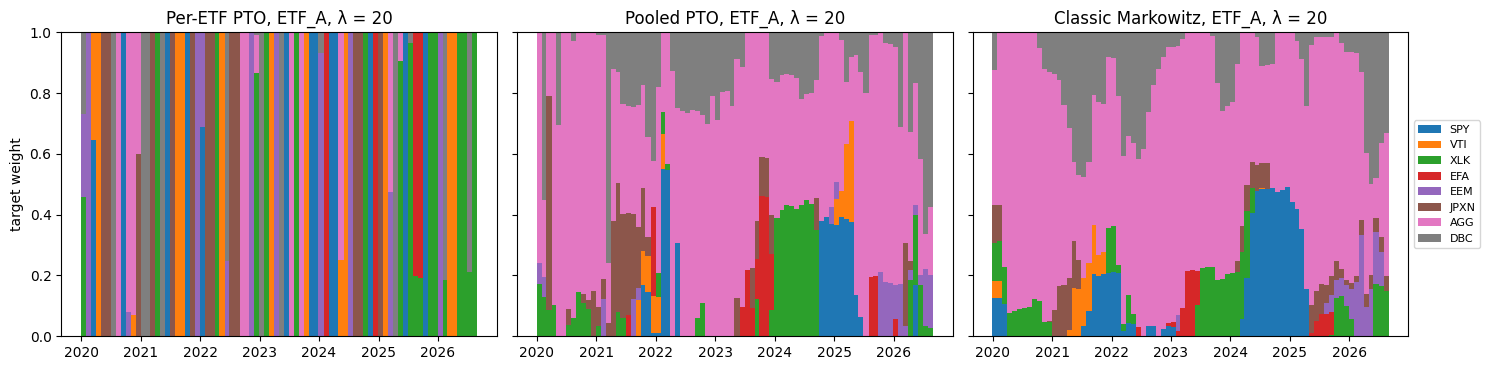

lam                         0.1   1.0   10.0  20.0  50.0
strategy          universe                              
Classic Markowitz ETF_A     0.99  0.61  0.00  0.10  0.17
                  ETF_B     0.83  0.60  0.00  0.00  0.00
Per-ETF PTO       ETF_A     1.00  1.00  0.89  0.86  0.57
                  ETF_B     1.00  1.00  0.91  0.86  0.69
Pooled PTO        ETF_A     0.99  0.84  0.03  0.04  0.07
                  ETF_B     1.00  0.63  0.06  0.03  0.03


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
colors = plt.cm.tab10(np.arange(len(config.ETF_A)))
for ax, name in zip(axes, ("Per-ETF PTO", "Pooled PTO", "Classic Markowitz")):
    w = weights_by_run[(name, "ETF_A", 20.0)].pivot(index="date", columns="ticker", values="target")[config.ETF_A]
    ax.stackplot(w.index, w.T.to_numpy(), labels=config.ETF_A, colors=colors, step="post")
    ax.set_title(f"{name}, ETF_A, λ = 20")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("target weight")
axes[2].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

# Share of months with one ETF above 90%
last = pd.Timestamp(config.PAPER_LAST_MONTH) - pd.offsets.MonthEnd(1)
single = pd.DataFrame([{"strategy": n, "universe": u, "lam": l,
                        "share": (w.groupby("date")["target"].max().loc[:last] > 0.9).mean()}
                       for (n, u, l), w in weights_by_run.items()])
print(single.pivot_table(index=["strategy", "universe"], columns="lam", values="share").round(2).to_string())

## 10. Save

In [11]:
proc = DIRS["processed"]
fc_per_etf.to_parquet(proc / "Per-ETF PTO Forecasts.parquet", index=False)
rep_months.to_parquet(proc / "Replication Months (per-ETF).parquet", index=False)
results = pd.concat([side_by_side(full).assign(window="81 months"), comparison70.assign(window="70 months")])
results.reset_index().to_csv(DIRS["reports"] / "Replication Results (per-ETF).csv", index=False)
all_checks = pd.concat(checks, ignore_index=True)
all_checks.to_csv(DIRS["reports"] / "Replication Checks (per-ETF).csv", index=False)

## 11. Summary

In [12]:
# Key figures
a = comparison70.xs("ETF_A", level="universe")
for name in ("Per-ETF PTO", "Pooled PTO", "Classic Markowitz"):
    line = f"ETF_A, 70 months, {name} turnover: {a.loc[name, 'turnover'].min():.2f} to {a.loc[name, 'turnover'].max():.2f}"
    if name != "Pooled PTO":
        line += f" (paper {a.loc[name, 'paper_turnover'].min():.2f} to {a.loc[name, 'paper_turnover'].max():.2f})"
    print(line)
print(f"Pass criteria (ETF_A): {', '.join(criteria.loc[criteria['universe'] == 'ETF_A', 'status'])}")
print(f"Checks: {(all_checks['status'] == 'PASS').sum()} passed, {(all_checks['status'] == 'FAIL').sum()} failed")

ETF_A, 70 months, Per-ETF PTO turnover: 0.76 to 0.82 (paper 0.83 to 0.84)
ETF_A, 70 months, Pooled PTO turnover: 0.10 to 0.35
ETF_A, 70 months, Classic Markowitz turnover: 0.05 to 0.18 (paper 0.04 to 0.25)
Pass criteria (ETF_A): PASS, PASS, PASS, PASS
Checks: 170 passed, 0 failed
